Effects of imbalance on balanced accuracy

Bootstrapping the results of different imbalance datasets

In [8]:
from pathlib import Path
import pandas as pd
import os

base_path = Path(r'Q:\Abteilungsprojekte\uchem\Projekte\Aktuelle Projekte\1179_MLinvitroTox\MLinvitroTox_PosNeg\mlinvitrotox\data\input\invitro\pytcpl')
aeids = ['97', '103', '113', '134', '135', '804', '1134', '1816', '2057', '2108', '2127', '2130', '2131'] #data imbalance aeids


og_dir = r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\Imbalance\Imbalance_n_constant_500"
root_dirs = ["Imbalance_01", "Imbalance_05", "Imbalance_15", "Imbalance_20", "Imbalance_25", "Imbalance_50"]

metrics_list = []

for root_dir in root_dirs:

    root_data_dir = os.path.join(og_dir, root_dir, "class")

    for aeid in aeids:

        base_path = os.path.join(
            root_data_dir,
            str(aeid),
        )

        pred_file = os.path.join(base_path, "FS_RandomForest", "mb_val_structure","test_predictions_default.csv")
        chem_file = os.path.join(base_path, "test_true_chemicals.csv")

        if not (os.path.isfile(pred_file) and os.path.isfile(chem_file)):
            continue

        preds = pd.read_csv(pred_file)
        chems = pd.read_csv(chem_file)

        # Merge safely (index-based only if you are 100% sure they align)
        df = chems.merge(preds, left_index=True, right_index=True)

        df["correct"] = (df["y_true"] == df["y_pred"]).astype(int)

        # Add identifiers
        df["aeid"] = aeid
        df["data"] = root_dir   # this is your 25%, 50%, etc.

        metrics_list.append(df)

# Final dataframe
metrics_df = pd.concat(metrics_list, ignore_index=True)

In [9]:
import numpy as np
from sklearn.metrics import f1_score, balanced_accuracy_score


def bootstrap_predictions(metrics_df, n_boot=1000):

    bootstrap_results = []

    for aeid in metrics_df["aeid"].unique():

        aeid_df = metrics_df[
            metrics_df["aeid"] == aeid
        ].copy()

        abundances = aeid_df["data"].unique()

        # Make sure all models predict same compounds
        grouped = {
            abundance: df.reset_index(drop=True)
            for abundance, df in aeid_df.groupby("data")
        }

        n_samples = len(next(iter(grouped.values())))

        for b in range(n_boot):

            idx = np.random.choice(
                n_samples,
                size=n_samples,
                replace=True
            )

            for abundance, df in grouped.items():

                yt = df.loc[idx, "y_true"]
                yp = df.loc[idx, "y_pred"]

                bootstrap_results.append({
                    "aeid": aeid,
                    "data": abundance,
                    "bootstrap": b,
                    "f1_micro": f1_score(
                        yt,
                        yp,
                        average="micro"
                    ),
                    "balanced_accuracy": balanced_accuracy_score(
                        yt,
                        yp
                    )
                })

    return pd.DataFrame(bootstrap_results)


In [10]:
boot_df = bootstrap_predictions(
    metrics_df,
    n_boot=1000
)

In [11]:
boot_melted = boot_df.melt(
    id_vars=["aeid", "data", "bootstrap"],
    value_vars=[
        "balanced_accuracy"
    ],
    var_name="metric",
    value_name="score"
)

C:\Users\aischlen\AppData\Local\Temp\ipykernel_23160\756794980.py:48: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


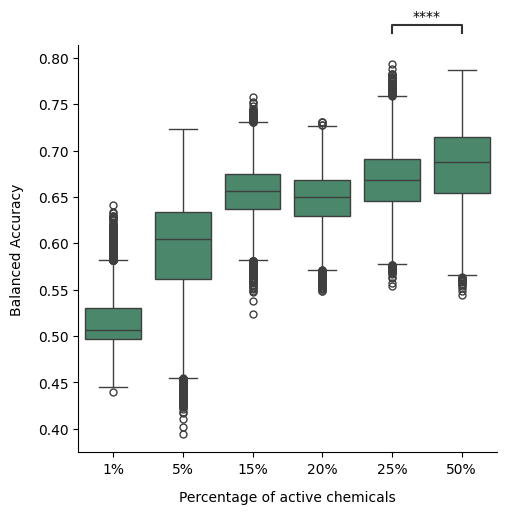

In [ ]:
from statannotations.Annotator import Annotator
import seaborn as sns
import matplotlib.pyplot as plt

metric_order = [
    "balanced_accuracy"
]
data_order = [ "Imbalance_01", "Imbalance_05", "Imbalance_15", "Imbalance_20", "Imbalance_25", "Imbalance_50"]

g = sns.catplot(
    data=boot_melted,
    x="data",
    y="score",
    order=data_order,
    col="metric",
    col_order=metric_order,
    kind="box",
    #inner=None,
    height=5,
    aspect=1,
    color="#40916c"
)
sns.despine()

label_map = {
    "Imbalance_01": "1%",
    "Imbalance_05": "5%",
    "Imbalance_15": "15%",
    "Imbalance_20": "20%",
    "Imbalance_25": "25%",
    "Imbalance_50": "50%"
}

title_map = {
    'balanced_accuracy': 'Balanced Accuracy and Imbalance'
}

pairs = [
    #("Imbalance_50", "Imbalance_01"),
    #("Imbalance_50", "Imbalance_05"),
    #("Imbalance_50", "Imbalance_15"),
    ("Imbalance_50", "Imbalance_25"),
    #("Imbalance_50", "Imbalance_20"),
]

g.set_titles("")
for ax in g.axes.flat:
    ax.set_xticklabels(
        [label_map[x] for x in data_order]
    )   


for ax, metric in zip(g.axes.flat, metric_order):
    subset = boot_melted[boot_melted["metric"] == metric]

    annotator = Annotator(
        ax,
        pairs,
        data=subset,
        x="data",
        y="score",
        order=data_order
    )

    annotator.configure(
        test="Mann-Whitney",
        text_format="star",
        loc="outside",
        verbose=0
    )

    annotator.apply_and_annotate()

ax.set_xlabel("Percentage of active chemicals", labelpad=10)
ax.set_ylabel("Balanced Accuracy", labelpad=10)

#plt.savefig("figure_imbalance_n500.svg", bbox_inches="tight")

plt.show()

Oversampling or not?

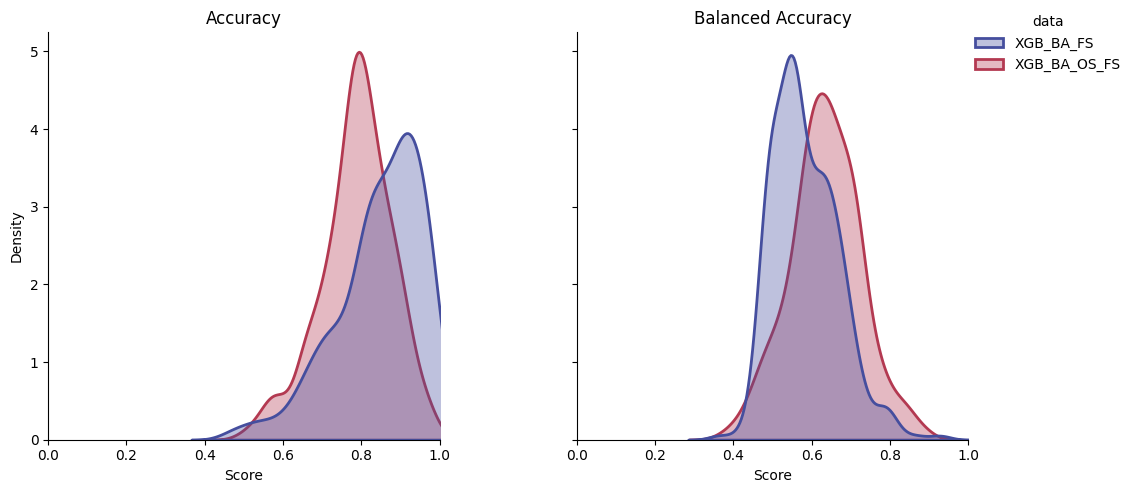

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

metrics_df = pd.read_csv(r'Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\MLinvitroTox_PosNeg\src\mlinvitrotox\Eval_figures\OS_noOS_metrics.csv')

df_plot = metrics_df.melt(
    id_vars=["data", "aeid"],
    value_vars=["accuracy", "balanced_accuracy"],
    var_name="metric",
    value_name="score"
)

# Prettier labels
metric_labels = {
    'balanced_accuracy': 'Balanced Accuracy',
    'accuracy': 'F1 Micro'
}
df_plot['metric'] = df_plot['metric'].map(metric_labels)

palette = {
    'XGB_BA_FS': '#454e9e',
    'XGB_BA_OS_FS': '#b33951',
}
hue_order = list(palette.keys())

# Desired panel order
metric_order = ['F1 Micro', 'Balanced Accuracy']
title_map = {
    'F1 Micro': 'Accuracy',
    'Balanced Accuracy': 'Balanced Accuracy'
}

g = sns.displot(
    data=df_plot,
    x='score',
    hue='data',
    col='metric',
    col_order=metric_order,
    kind='kde',
    fill=True,
    common_norm=False,
    alpha=0.35,
    linewidth=2,
    height=5,
    aspect=1,
    palette=palette,
    hue_order=hue_order
)

# Labels
g.set_axis_labels('Score', 'Density')
g.set(xlim=(0, 1))

for ax, metric in zip(g.axes.flat, metric_order):
    ax.set_title(title_map[metric])

# Space between panels
g.fig.subplots_adjust(wspace=0.35)

# Legend upper right
if g._legend is not None:
    g._legend.set_bbox_to_anchor((0.98, 0.98))
    g._legend._loc = 1

plt.show()